# 01 — Comprehensive Data Audit & Exploratory Data Analysis (EDA)
**Project:** Insurance Claim Fraud Detection — Major Project Phase 1  
**Objective:** Perform a rigorous statistical audit of the claims dataset, detect data quality defects (e.g. `'?'` sentinel values, zero variance fields), inspect the 24.7% class imbalance, examine correlation structures, and validate claim consistency.

In [1]:
from pathlib import Path

import sys

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns



# Add src to path

sys.path.insert(0, str(Path.cwd().parent))

from src.config import RAW_DATA_PATH, TARGET_COL, TARGET_MAPPING

from src.data_loader import load_raw_data, parse_dates_and_target



sns.set_theme(style='whitegrid')

pd.set_option('display.max_columns', 50)

## 1. Load Data with Explicit '?' Sentinel Value Handling

In [2]:
# Load claims raw data

raw_df = load_raw_data(RAW_DATA_PATH)

print(f'Total Claim Records: {len(raw_df):,}')

print(f'Total Attributes: {raw_df.shape[1]}')

raw_df.head(3)

Total Claim Records: 1,000
Total Attributes: 39


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,2015-01-25,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,2015-01-21,Vehicle Theft,NaN,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,NaN,0,0,NaN,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,2015-02-22,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N


## 2. Missing Value & Data Quality Audit
Notice how `collision_type`, `property_damage`, and `police_report_available` contained `'?'` characters in the original data. We now recognize them as real missing values.

In [3]:
missing_summary = pd.DataFrame({

    'missing_count': raw_df.isna().sum(),

    'missing_pct': (raw_df.isna().mean() * 100).round(2)

}).query('missing_count > 0').sort_values('missing_count', ascending=False)



print('Features with Missing Values:')

display(missing_summary)

Features with Missing Values:


,missing_count,missing_pct
property_damage,360,36.0
police_report_available,343,34.3
collision_type,178,17.8
authorities_contacted,91,9.1


## 3. Fraud Target Distribution
Fraud claims represent ~24.7% of the dataset. Accuracy alone will be misleading; we must track Precision, Recall, F1, and PR-AUC.

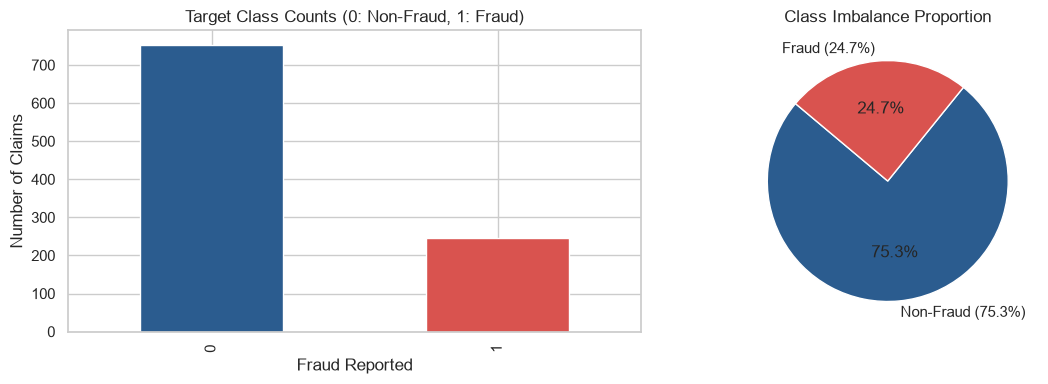

In [4]:
clean_df = parse_dates_and_target(raw_df)

target_counts = clean_df[TARGET_COL].value_counts()



fig, axes = plt.subplots(1, 2, figsize=(12, 4))

target_counts.plot(kind='bar', color=['#2b5c8f', '#d9534f'], ax=axes[0])

axes[0].set_title('Target Class Counts (0: Non-Fraud, 1: Fraud)')

axes[0].set_xlabel('Fraud Reported')

axes[0].set_ylabel('Number of Claims')



axes[1].pie(target_counts, labels=['Non-Fraud (75.3%)', 'Fraud (24.7%)'], autopct='%1.1f%%', colors=['#2b5c8f', '#d9534f'], startangle=140)

axes[1].set_title('Class Imbalance Proportion')

plt.tight_layout()

plt.show()

## 4. Financial Component Consistency Check
Validating that `total_claim_amount == injury_claim + property_claim + vehicle_claim`.

In [5]:
component_sum = clean_df['injury_claim'] + clean_df['property_claim'] + clean_df['vehicle_claim']

discrepancy = (clean_df['total_claim_amount'] - component_sum).abs()

print(f'Max discrepancy between total claim and component sum: ${discrepancy.max():.2f}')

assert discrepancy.max() == 0, 'Discrepancy detected in claim accounting!'

Max discrepancy between total claim and component sum: $0.00


## 5. Fraud Rate Across Key Categorical Features

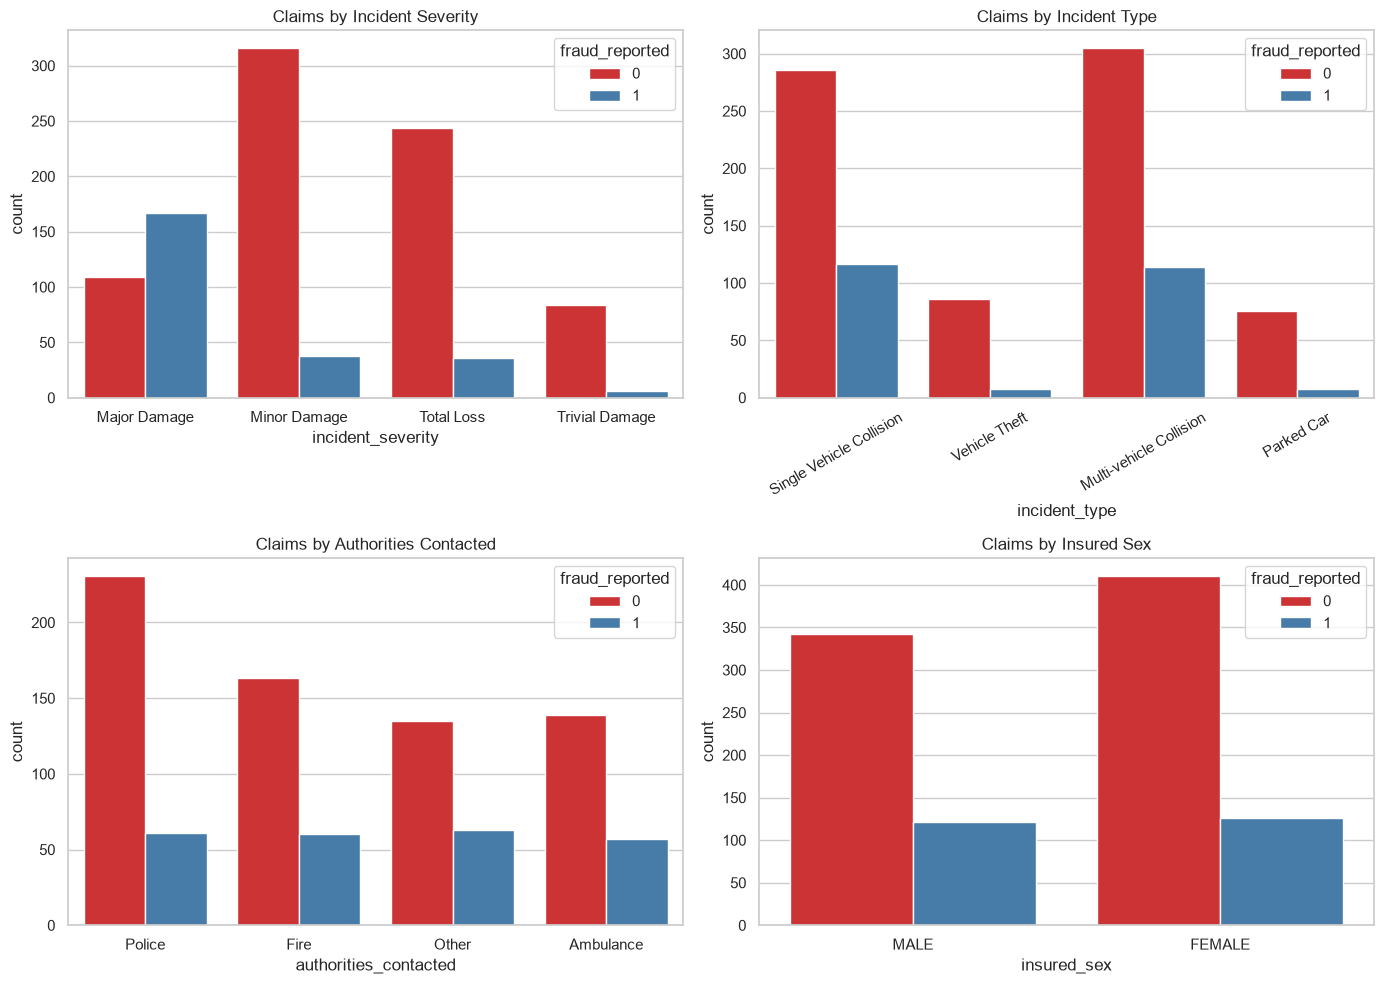

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=clean_df, x='incident_severity', hue=TARGET_COL, palette='Set1', ax=axes[0, 0])

axes[0, 0].set_title('Claims by Incident Severity')



sns.countplot(data=clean_df, x='incident_type', hue=TARGET_COL, palette='Set1', ax=axes[0, 1])

axes[0, 1].set_title('Claims by Incident Type')

axes[0, 1].tick_params(axis='x', rotation=30)



sns.countplot(data=clean_df, x='authorities_contacted', hue=TARGET_COL, palette='Set1', ax=axes[1, 0])

axes[1, 0].set_title('Claims by Authorities Contacted')



sns.countplot(data=clean_df, x='insured_sex', hue=TARGET_COL, palette='Set1', ax=axes[1, 1])

axes[1, 1].set_title('Claims by Insured Sex')

plt.tight_layout()

plt.show()